# Social Media Engagement Analytics Using Python

In [185]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import warnings
warnings.filterwarnings('ignore')

## Data Import & Setup

In [186]:
data = pd.read_csv(r"C:\Users\akshaya\OneDrive\Documents\ENTRI\Python\social_media_engagement_5000.csv")
data.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [187]:
data.shape

(5000, 19)

In [188]:
data.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='object')

In [189]:
data.dtypes

user_id               int64
age                 float64
gender               object
country              object
post_id               int64
post_type            object
post_category        object
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at            object
follower_count        int64
is_verified            bool
device_type          object
sentiment            object
hashtags             object
engagement_rate     float64
dtype: object

In [190]:
data['posted_at'] = pd.to_datetime(data['posted_at'])
data['posted_at'].dtype

dtype('<M8[ns]')

In [191]:
likes_array = np.array(data['likes'].dropna())

print("First 5 likes:", likes_array[:5])
print("Total likes:", np.sum(likes_array))
print("Average likes:", np.mean(likes_array))
print("Maximum likes:", np.max(likes_array))
print("Minimum likes:", np.min(likes_array))

First 5 likes: [ 7011. 11750.  4862.  5350. 12682.]
Total likes: 49019162.0
Average likes: 10107.043711340206
Maximum likes: 19998.0
Minimum likes: 10.0


## Data Cleaning

> #### Cleaning Missing Data

In [192]:
cleaned_data = data.copy()

In [193]:
print(cleaned_data.isnull().sum())
print()
print("Total missing values")
print(cleaned_data.isnull().sum().sum())

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

Total missing values
900


In [194]:
cleaned_data['age'] = cleaned_data['age'].fillna(cleaned_data['age'].median())

cleaned_data['likes'] = cleaned_data['likes'].fillna(cleaned_data['likes'].median())

cleaned_data['comments'] = cleaned_data['comments'].fillna(cleaned_data['comments'].median())

cleaned_data['shares'] = cleaned_data['shares'].fillna(cleaned_data['shares'].median())

In [195]:
cleaned_data['gender'] = cleaned_data['gender'].fillna(cleaned_data['gender'].mode()[0])

cleaned_data['sentiment'] = cleaned_data['sentiment'].fillna(cleaned_data['sentiment'].mode()[0])

In [196]:
cleaned_data.isnull().sum()

user_id             0
age                 0
gender              0
country             0
post_id             0
post_type           0
post_category       0
likes               0
comments            0
shares              0
watch_time_sec      0
impression_count    0
posted_at           0
follower_count      0
is_verified         0
device_type         0
sentiment           0
hashtags            0
engagement_rate     0
dtype: int64

> #### Duplicate Handling

In [197]:
cleaned_data.duplicated().sum()

np.int64(0)

In [198]:
cleaned_data = cleaned_data.drop_duplicates()

In [199]:
print("Total rows after removing duplicates:", cleaned_data.shape[0])
print("Total duplicate rows:", cleaned_data.duplicated().sum())

Total rows after removing duplicates: 5000
Total duplicate rows: 0


> #### Data Formatting

In [200]:
cleaned_data.dtypes

user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
dtype: object

In [201]:
print("Gender values:")
print(cleaned_data['gender'].unique())

print("\nPost Type values:")
print(cleaned_data['post_type'].unique())

print("\nPost Category values:")
print(cleaned_data['post_category'].unique())

print("\nSentiment values:")
print(cleaned_data['sentiment'].unique())

print("\nDevice Type values:")
print(cleaned_data['device_type'].unique())

Gender values:
['Female' 'Male' 'Other']

Post Type values:
['image' 'reel' 'text' 'video']

Post Category values:
['fitness' 'food' 'tech' 'travel' 'fashion' 'lifestyle' 'education'
 'music']

Sentiment values:
['negative' 'positive' 'neutral']

Device Type values:
['mobile' 'tablet' 'desktop']


In [202]:
text_columns = ['gender', 'country', 'post_type',
                'post_category', 'sentiment', 'device_type']

for col in text_columns:
    cleaned_data[col] = cleaned_data[col].str.strip().str.lower()

In [203]:
for col in text_columns:
    print("\n", col)
    print(cleaned_data[col].unique())


 gender
['female' 'male' 'other']

 country
['brazil' 'uk' 'france' 'canada' 'japan' 'australia' 'india' 'uae'
 'germany' 'usa']

 post_type
['image' 'reel' 'text' 'video']

 post_category
['fitness' 'food' 'tech' 'travel' 'fashion' 'lifestyle' 'education'
 'music']

 sentiment
['negative' 'positive' 'neutral']

 device_type
['mobile' 'tablet' 'desktop']


In [204]:
print("Negative likes:", (cleaned_data['likes'] < 0).sum())

print("Negative comments:", (cleaned_data['comments'] < 0).sum())

print("Negative shares:", (cleaned_data['shares'] < 0).sum())

print("Negative age:", (cleaned_data['age'] < 0).sum())

Negative likes: 0
Negative comments: 0
Negative shares: 0
Negative age: 0


In [205]:
print("Maximum likes:", cleaned_data['likes'].max())

print("Maximum comments:", cleaned_data['comments'].max())

print("Maximum shares:", cleaned_data['shares'].max())

print("Maximum age:", cleaned_data['age'].max())

Maximum likes: 19998.0
Maximum comments: 2999.0
Maximum shares: 1999.0
Maximum age: 64.0


In [206]:
print("Decimal likes:", (cleaned_data['likes'] % 1 != 0).sum())

print("Decimal comments:", (cleaned_data['comments'] % 1 != 0).sum())

print("Decimal shares:", (cleaned_data['shares'] % 1 != 0).sum())

Decimal likes: 150
Decimal comments: 0
Decimal shares: 0


In [207]:
print("Minimum age:", cleaned_data['age'].min())
print("Maximum age:", cleaned_data['age'].max())

Minimum age: 13.0
Maximum age: 64.0


In [208]:
cleaned_data['likes'] = cleaned_data['likes'].round().astype(int)

In [209]:
cleaned_data['comments'] = cleaned_data['comments'].astype(int)

cleaned_data['shares'] = cleaned_data['shares'].astype(int)

In [210]:
print(cleaned_data[['likes', 'comments', 'shares', 'age']].dtypes)

likes         int64
comments      int64
shares        int64
age         float64
dtype: object


In [211]:
print("Total missing values:", cleaned_data.isnull().sum().sum())

Total missing values: 0


> #### Feature Cleaning

In [212]:
print(cleaned_data['hashtags'].head(10))

0      #foodie #travel #love
1                   #fitness
2                    #foodie
3        #music #foodie #fun
4                    #travel
5                   #fitness
6                     #music
7    #travel #music #fitness
8       #music #fun #fitness
9           #lifestyle #love
Name: hashtags, dtype: object


In [213]:
cleaned_data['hashtags'] = cleaned_data['hashtags'].str.lower()

In [214]:
cleaned_data['hashtags'] = cleaned_data['hashtags'].str.strip()

In [215]:
cleaned_data['hashtags'] = cleaned_data['hashtags'].str.replace(r'[^\w\s#]', '', regex=True)

In [216]:
print(cleaned_data['hashtags'].head(10))

0      #foodie #travel #love
1                   #fitness
2                    #foodie
3        #music #foodie #fun
4                    #travel
5                   #fitness
6                     #music
7    #travel #music #fitness
8       #music #fun #fitness
9           #lifestyle #love
Name: hashtags, dtype: object


In [217]:
cleaned_data['hashtag_count'] = cleaned_data['hashtags'].str.findall(r'#\w+').str.len()

In [218]:
cleaned_data[['hashtags', 'hashtag_count']].head(10)

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [219]:
print("Total hashtags:", cleaned_data['hashtag_count'].sum())

print("Average hashtags per post:", cleaned_data['hashtag_count'].mean())

print("Maximum hashtags in a post:", cleaned_data['hashtag_count'].max())

Total hashtags: 9993
Average hashtags per post: 1.9986
Maximum hashtags in a post: 3


In [220]:
print("Sentiment categories:")
print(cleaned_data['sentiment'].unique())

print("\nSentiment counts:")
print(cleaned_data['sentiment'].value_counts())

Sentiment categories:
['negative' 'positive' 'neutral']

Sentiment counts:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [221]:
valid_sentiments = ['positive', 'negative', 'neutral']

invalid_sentiments = cleaned_data[
    ~cleaned_data['sentiment'].isin(valid_sentiments)]

print("Invalid sentiment records:", len(invalid_sentiments))

Invalid sentiment records: 0


In [222]:
cleaned_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-null   int64         
 14  is_verified       5000 n

In [223]:
print("Total missing values:", cleaned_data.isnull().sum().sum())

Total missing values: 0


In [224]:
print("Total duplicate rows:", cleaned_data.duplicated().sum())

Total duplicate rows: 0


In [225]:
cleaned_data.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


## Data Exploration using Pandas

In [226]:
print("First 5 records:")
display(cleaned_data.head())

print("Last 5 records:")
display(cleaned_data.tail())

First 5 records:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,brazil,496713,image,fitness,7011,354,1157,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,brazil,157326,reel,food,11750,2606,1807,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,uk,109864,text,food,4862,344,955,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,france,848877,text,fitness,5350,1083,1049,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,uk,449706,image,fitness,12682,2735,1300,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


Last 5 records:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.0,male,australia,441541,video,education,16210,2013,1837,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,uae,677076,reel,education,16924,2734,1583,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4997,67021,63.0,female,usa,273595,text,travel,13487,1497,167,7466,23680,2023-04-06,483550,False,desktop,positive,#lifestyle #tech,0.679688,2
4998,29800,13.0,female,germany,785644,video,fitness,16894,1289,1713,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,japan,712252,text,travel,14830,503,1798,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [227]:
cleaned_data.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='object')

In [228]:
print(cleaned_data.dtypes)

user_id                      int64
age                        float64
gender                      object
country                     object
post_id                      int64
post_type                   object
post_category               object
likes                        int64
comments                     int64
shares                       int64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[ns]
follower_count               int64
is_verified                   bool
device_type                 object
sentiment                   object
hashtags                    object
engagement_rate            float64
hashtag_count                int64
dtype: object


In [229]:
print("Dataset shape:", cleaned_data.shape)

print("\nDataset information:")
cleaned_data.info()

Dataset shape: (5000, 20)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            5000 non-null   object        
 3   country           5000 non-null   object        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   object        
 6   post_category     5000 non-null   object        
 7   likes             5000 non-null   int64         
 8   comments          5000 non-null   int64         
 9   shares            5000 non-null   int64         
 10  watch_time_sec    5000 non-null   int64         
 11  impression_count  5000 non-null   int64         
 12  posted_at         5000 non-null   datetime64[ns]
 13  follower_count    5000 non-nul

In [230]:
cleaned_data.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.0000,5000.000000,5000.000000,5000,5000.000000,5000.000000,5000.000000
mean,54561.890800,38.440400,548042.909000,10107.012400,1502.039800,1002.9106,4014.503200,50013.732800,2022-12-28 13:21:30.240000,393698.224800,0.964356,1.998600
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.0000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32309.500000,26.000000,322543.500000,5235.000000,792.000000,511.0000,2017.750000,24988.250000,2022-07-03 18:00:00,194480.000000,0.145781,1.000000
50%,54374.500000,38.000000,548077.500000,10106.000000,1497.000000,1012.0000,4034.500000,49934.500000,2022-12-27 00:00:00,388982.000000,0.253896,2.000000
75%,77180.500000,51.000000,771574.500000,14959.000000,2235.250000,1483.0000,6020.250000,74662.250000,2023-06-28 00:00:00,589744.250000,0.504794,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.0000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,26090.370121,14.687151,260646.957267,5702.293014,856.393312,570.8552,2308.096459,28844.939104,NaN,230927.884535,5.318029,0.812853


In [231]:
print("Post Type Counts:")
print(cleaned_data['post_type'].value_counts())

print("\nPost Category Counts:")
print(cleaned_data['post_category'].value_counts())

print("\nCountry Counts:")
print(cleaned_data['country'].value_counts())

print("\nDevice Type Counts:")
print(cleaned_data['device_type'].value_counts())

print("\nSentiment Counts:")
print(cleaned_data['sentiment'].value_counts())

Post Type Counts:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: int64

Post Category Counts:
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       600
fashion      594
food         593
Name: count, dtype: int64

Country Counts:
country
india        535
canada       513
brazil       504
uae          503
usa          501
france       496
uk           493
australia    493
germany      490
japan        472
Name: count, dtype: int64

Device Type Counts:
device_type
mobile     1684
tablet     1658
desktop    1658
Name: count, dtype: int64

Sentiment Counts:
sentiment
positive    2513
neutral     1527
negative     960
Name: count, dtype: int64


In [232]:
print("Unique post types:", cleaned_data['post_type'].unique())

print("\nNumber of unique post categories:",
      cleaned_data['post_category'].nunique())

print("\nUnique countries:", cleaned_data['country'].unique())

print("\nUnique sentiments:", cleaned_data['sentiment'].unique())

Unique post types: ['image' 'reel' 'text' 'video']

Number of unique post categories: 8

Unique countries: ['brazil' 'uk' 'france' 'canada' 'japan' 'australia' 'india' 'uae'
 'germany' 'usa']

Unique sentiments: ['negative' 'positive' 'neutral']


category_analysis = cleaned_data.groupby('post_category').agg(
    Total_Posts=('post_id', 'count'),
    Average_Likes=('likes', 'mean'),
    Average_Comments=('comments', 'mean'),
    Average_Shares=('shares', 'mean'),
    Average_Engagement=('engagement_rate', 'mean')
)

display(category_analysis)

In [233]:
numeric_data = cleaned_data.select_dtypes(include=np.number)

correlation = numeric_data.corr()

display(correlation)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate,hashtag_count
user_id,1.000000,-0.006688,0.020051,0.025811,-0.033395,0.013763,-0.016847,0.015326,0.010124,-0.004282,-0.013692
age,-0.006688,1.000000,-0.013153,-0.036322,-0.007284,0.013871,0.005542,0.013322,-0.024894,0.008039,0.007173
post_id,0.020051,-0.013153,1.000000,0.014527,-0.010540,0.001846,0.018374,-0.007709,-0.002844,0.010139,0.007344
likes,0.025811,-0.036322,0.014527,1.000000,-0.018421,0.004712,0.008711,0.007952,-0.022982,0.093520,-0.002189
comments,-0.033395,-0.007284,-0.010540,-0.018421,1.000000,0.006142,-0.016351,-0.009395,-0.011733,0.000051,-0.015230
shares,0.013763,0.013871,0.001846,0.004712,0.006142,1.000000,0.014658,-0.005204,-0.010783,0.021724,0.013379
watch_time_sec,-0.016847,0.005542,0.018374,0.008711,-0.016351,0.014658,1.000000,-0.004335,0.002761,-0.001148,-0.023301
impression_count,0.015326,0.013322,-0.007709,0.007952,-0.009395,-0.005204,-0.004335,1.000000,-0.015513,-0.232226,-0.002714
follower_count,0.010124,-0.024894,-0.002844,-0.022982,-0.011733,-0.010783,0.002761,-0.015513,1.000000,0.002292,0.008802
engagement_rate,-0.004282,0.008039,0.010139,0.093520,0.000051,0.021724,-0.001148,-0.232226,0.002292,1.000000,0.005319


## Data Wrangling

In [234]:
wrangled_data = cleaned_data.copy()

print("Original dataset shape:", cleaned_data.shape)
print("Wrangled dataset shape:", wrangled_data.shape)

Original dataset shape: (5000, 20)
Wrangled dataset shape: (5000, 20)


In [235]:
# Create engagement_score
wrangled_data['engagement_score'] = (
    wrangled_data['likes'] +
    wrangled_data['comments'] +
    wrangled_data['shares'])

display(wrangled_data[
    ['likes', 'comments', 'shares', 'engagement_score']].head())

,likes,comments,shares,engagement_score
0,7011,354,1157,8522
1,11750,2606,1807,16163
2,4862,344,955,6161
3,5350,1083,1049,7482
4,12682,2735,1300,16717


In [236]:
# Create log-transformed metrics
wrangled_data['log_likes'] = np.log1p(wrangled_data['likes'])

wrangled_data['log_comments'] = np.log1p(wrangled_data['comments'])

wrangled_data['log_shares'] = np.log1p(wrangled_data['shares'])

wrangled_data['log_engagement_score'] = np.log1p(
    wrangled_data['engagement_score'])

display(wrangled_data[
    ['engagement_score', 'log_likes',
     'log_comments', 'log_shares',
     'log_engagement_score']].head())

,engagement_score,log_likes,log_comments,log_shares,log_engagement_score
0,8522,8.855378,5.872118,7.054450,9.050524
1,16163,9.371694,7.865955,7.499977,9.690542
2,6161,8.489411,5.843544,6.862758,8.726157
3,7482,8.585039,6.988413,6.956545,8.920389
4,16717,9.448018,7.914252,7.170888,9.724241


In [237]:
# Create hashtag_count
if 'hashtag_count' not in wrangled_data.columns:
    wrangled_data['hashtag_count'] = (
        wrangled_data['hashtags'].str.findall(r'#\w+').str.len())

display(wrangled_data[['hashtags', 'hashtag_count']].head(10))

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


In [238]:
# Create a separate DataFrame for post details
post_details = wrangled_data[
    ['post_id', 'post_type', 'post_category', 'country']]

display(post_details.head())

,post_id,post_type,post_category,country
0,496713,image,fitness,brazil
1,157326,reel,food,brazil
2,109864,text,food,uk
3,848877,text,fitness,france
4,449706,image,fitness,uk


In [239]:
# Create a separate DataFrame for engagement details
engagement_details = wrangled_data[
    ['post_id', 'likes', 'comments', 'shares',
     'engagement_score', 'engagement_rate']]

display(engagement_details.head())

,post_id,likes,comments,shares,engagement_score,engagement_rate
0,496713,7011,354,1157,8522,0.190862
1,157326,11750,2606,1807,16163,0.201493
2,109864,4862,344,955,6161,0.137345
3,848877,5350,1083,1049,7482,0.106195
4,449706,12682,2735,1300,16717,2.777372


In [240]:
# Merge two DataFrames
merged_data = pd.merge(
    post_details,
    engagement_details,
    on='post_id',
    how='inner')

display(merged_data.head())

print("Merged dataset shape:", merged_data.shape)

,post_id,post_type,post_category,country,likes,comments,shares,engagement_score,engagement_rate
0,496713,image,fitness,brazil,7011,354,1157,8522,0.190862
1,157326,reel,food,brazil,11750,2606,1807,16163,0.201493
2,109864,text,food,uk,4862,344,955,6161,0.137345
3,848877,text,fitness,france,5350,1083,1049,7482,0.106195
4,449706,image,fitness,uk,12682,2735,1300,16717,2.777372


Merged dataset shape: (5018, 9)


In [241]:
# Concatenate DataFrames
first_half = wrangled_data.iloc[:2500]

second_half = wrangled_data.iloc[2500:]

combined_data = pd.concat(
    [first_half, second_half],
    axis=0,
    ignore_index=True)

print("First half:", first_half.shape)
print("Second half:", second_half.shape)
print("Combined dataset:", combined_data.shape)

First half: (2500, 25)
Second half: (2500, 25)
Combined dataset: (5000, 25)


In [242]:
# Join DataFrames
post_info = post_details.set_index('post_id')

engagement_info = engagement_details.set_index('post_id')

joined_data = post_info.join(
    engagement_info,
    how='inner',
    lsuffix='_post',
    rsuffix='_engagement')

display(joined_data.head())

print("Joined dataset shape:", joined_data.shape)

,post_type,post_category,country,likes,comments,shares,engagement_score,engagement_rate
post_id,,,,,,,,
496713,image,fitness,brazil,7011,354,1157,8522,0.190862
157326,reel,food,brazil,11750,2606,1807,16163,0.201493
109864,text,food,uk,4862,344,955,6161,0.137345
848877,text,fitness,france,5350,1083,1049,7482,0.106195
449706,image,fitness,uk,12682,2735,1300,16717,2.777372


Joined dataset shape: (5018, 8)


In [243]:
# Groupby summary by post_type
post_type_summary = wrangled_data.groupby('post_type').agg(
    Total_Posts=('post_id', 'count'),
    Total_Likes=('likes', 'sum'),
    Average_Likes=('likes', 'mean'),
    Average_Comments=('comments', 'mean'),
    Average_Shares=('shares', 'mean'),
    Average_Engagement_Score=('engagement_score', 'mean'),
    Average_Engagement_Rate=('engagement_rate', 'mean')
).sort_values(
    by='Average_Engagement_Rate',
    ascending=False)

display(post_type_summary)

,Total_Posts,Total_Likes,Average_Likes,Average_Comments,Average_Shares,Average_Engagement_Score,Average_Engagement_Rate
post_type,,,,,,,
video,1225,12481052,10188.613878,1479.160000,996.834286,12664.608163,1.122365
text,1245,12574704,10100.163855,1499.106024,1013.989558,12613.259438,1.064549
image,1247,12600783,10104.878107,1525.235766,1019.289495,12649.403368,0.895646
reel,1283,12878523,10037.819953,1504.187062,982.042089,12524.049104,0.783047


In [244]:
# Groupby summary by sentiment
sentiment_summary = wrangled_data.groupby('sentiment').agg(
    Total_Posts=('post_id', 'count'),
    Average_Likes=('likes', 'mean'),
    Average_Comments=('comments', 'mean'),
    Average_Shares=('shares', 'mean'),
    Average_Engagement_Score=('engagement_score', 'mean'),
    Average_Engagement_Rate=('engagement_rate', 'mean')).sort_values(
    by='Average_Engagement_Rate',
    ascending=False)

display(sentiment_summary)

,Total_Posts,Average_Likes,Average_Comments,Average_Shares,Average_Engagement_Score,Average_Engagement_Rate
sentiment,,,,,,
negative,960,10208.112500,1516.094792,1007.307292,12731.514583,1.038486
neutral,1527,9923.208906,1528.404060,996.565160,12448.178127,0.991170
positive,2513,10180.077199,1480.650617,1005.086749,12665.814564,0.919744


In [245]:
print("Wrangled dataset shape:", wrangled_data.shape)

print("\nNewly created columns:")

new_columns = [
    'engagement_score',
    'log_likes',
    'log_comments',
    'log_shares',
    'log_engagement_score',
    'hashtag_count']

print(wrangled_data[new_columns].head())

print("\nMissing values in new columns:")
print(wrangled_data[new_columns].isnull().sum())

Wrangled dataset shape: (5000, 25)

Newly created columns:
   engagement_score  log_likes  log_comments  log_shares  \
0              8522   8.855378      5.872118    7.054450   
1             16163   9.371694      7.865955    7.499977   
2              6161   8.489411      5.843544    6.862758   
3              7482   8.585039      6.988413    6.956545   
4             16717   9.448018      7.914252    7.170888   

   log_engagement_score  hashtag_count  
0              9.050524              3  
1              9.690542              1  
2              8.726157              1  
3              8.920389              3  
4              9.724241              1  

Missing values in new columns:
engagement_score        0
log_likes               0
log_comments            0
log_shares              0
log_engagement_score    0
hashtag_count           0
dtype: int64


## Statistical Analysis 

In [246]:
columns_to_analyse = [
    'likes', 'comments', 'shares',
    'watch_time_sec', 'impression_count',
    'follower_count', 'engagement_rate'
]

for col in columns_to_analyse:
    print("\nColumn:", col)
    print("Mean:", cleaned_data[col].mean())
    print("Median:", cleaned_data[col].median())
    print("Mode:", cleaned_data[col].mode()[0])


Column: likes
Mean: 10107.0124
Median: 10106.0
Mode: 10106

Column: comments
Mean: 1502.0398
Median: 1497.0
Mode: 1497

Column: shares
Mean: 1002.9106
Median: 1012.0
Mode: 1012

Column: watch_time_sec
Mean: 4014.5032
Median: 4034.5
Mode: 916

Column: impression_count
Mean: 50013.7328
Median: 49934.5
Mode: 24207

Column: follower_count
Mean: 393698.2248
Median: 388982.0
Mode: 497502

Column: engagement_rate
Mean: 0.9643560291583999
Median: 0.2538959065
Mode: 0.006362909


In [247]:
for col in stat_columns:
    print("\nColumn:", col)
    print("Standard Deviation:", stat_data[col].std())
    print("Variance:", stat_data[col].var())


Column: likes
Standard Deviation: 5702.293013882179
Variance: 32516145.616169512

Column: comments
Standard Deviation: 856.3933120458967
Variance: 733409.5049169405

Column: shares
Standard Deviation: 570.8551999758862
Variance: 325875.65933950903

Column: watch_time_sec
Standard Deviation: 2308.096459042085
Variance: 5327309.26424261

Column: engagement_rate
Standard Deviation: 5.318029222661535
Variance: 28.281434813082043

Column: follower_count
Standard Deviation: 230927.88453461014
Variance: 53327687855.63023


In [248]:
for col in stat_columns:
    print("\nColumn:", col)
    print("25th Percentile:", stat_data[col].quantile(0.25))
    print("50th Percentile:", stat_data[col].quantile(0.50))
    print("75th Percentile:", stat_data[col].quantile(0.75))
    print("90th Percentile:", stat_data[col].quantile(0.90))


Column: likes
25th Percentile: 5235.0
50th Percentile: 10106.0
75th Percentile: 14959.0
90th Percentile: 18016.300000000003

Column: comments
25th Percentile: 792.0
50th Percentile: 1497.0
75th Percentile: 2235.25
90th Percentile: 2695.1000000000004

Column: shares
25th Percentile: 511.0
50th Percentile: 1012.0
75th Percentile: 1483.0
90th Percentile: 1795.1000000000004

Column: watch_time_sec
25th Percentile: 2017.75
50th Percentile: 4034.5
75th Percentile: 6020.25
90th Percentile: 7212.1

Column: engagement_rate
25th Percentile: 0.14578108750000002
50th Percentile: 0.2538959065
75th Percentile: 0.504793702
90th Percentile: 1.2011996101

Column: follower_count
25th Percentile: 194480.0
50th Percentile: 388982.0
75th Percentile: 589744.25
90th Percentile: 717755.9


In [249]:
for col in stat_columns:
    print("\nColumn:", col)
    print("Skewness:", stat_data[col].skew())
    print("Kurtosis:", stat_data[col].kurt())


Column: likes
Skewness: -0.0069015112638632775
Kurtosis: -1.1499922839841221

Column: comments
Skewness: 0.0038017289479831415
Kurtosis: -1.1443748352968992

Column: shares
Skewness: -0.014653583910311461
Kurtosis: -1.1468565626589917

Column: watch_time_sec
Skewness: -0.018196273193231846
Kurtosis: -1.195651797070188

Column: engagement_rate
Skewness: 18.781270878869154
Kurtosis: 482.9917386319569

Column: follower_count
Skewness: 0.04111777394961326
Kurtosis: -1.1894740478821386


In [250]:
descriptive_summary = stat_data.describe().T

descriptive_summary['mode'] = stat_data.mode().iloc[0]

descriptive_summary['variance'] = stat_data.var()

descriptive_summary['skewness'] = stat_data.skew()

descriptive_summary['kurtosis'] = stat_data.kurt()

display(descriptive_summary)

,count,mean,std,min,25%,50%,75%,max,mode,variance,skewness,kurtosis
likes,5000.0,10107.012400,5702.293014,10.000000,5235.000000,10106.000000,14959.000000,19998.000000,10106.000000,3.251615e+07,-0.006902,-1.149992
comments,5000.0,1502.039800,856.393312,0.000000,792.000000,1497.000000,2235.250000,2999.000000,1497.000000,7.334095e+05,0.003802,-1.144375
shares,5000.0,1002.910600,570.855200,0.000000,511.000000,1012.000000,1483.000000,1999.000000,1012.000000,3.258757e+05,-0.014654,-1.146857
watch_time_sec,5000.0,4014.503200,2308.096459,0.000000,2017.750000,4034.500000,6020.250000,7998.000000,916.000000,5.327309e+06,-0.018196,-1.195652
engagement_rate,5000.0,0.964356,5.318029,0.006363,0.145781,0.253896,0.504794,191.504348,0.006363,2.828143e+01,18.781271,482.991739
follower_count,5000.0,393698.224800,230927.884535,87.000000,194480.000000,388982.000000,589744.250000,799533.000000,497502.000000,5.332769e+10,0.041118,-1.189474


## Data Visualization

### Matplotlib

> <b> Scatter plot: Likes vs Impressions</b>

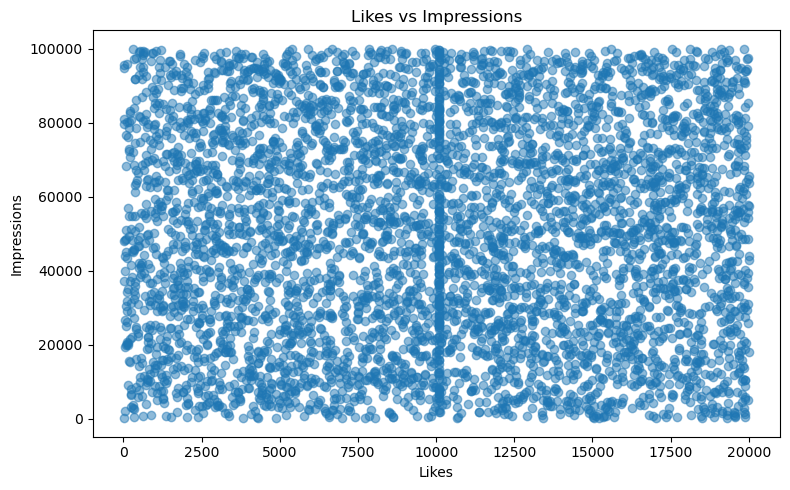

In [251]:
plt.figure(figsize=(8, 5))

plt.scatter(
    wrangled_data['likes'],
    wrangled_data['impression_count'],
    alpha=0.5)

plt.title('Likes vs Impressions')
plt.xlabel('Likes')
plt.ylabel('Impressions')
plt.tight_layout()
plt.show()

> <b>Line chart: Daily engagement trend</b>

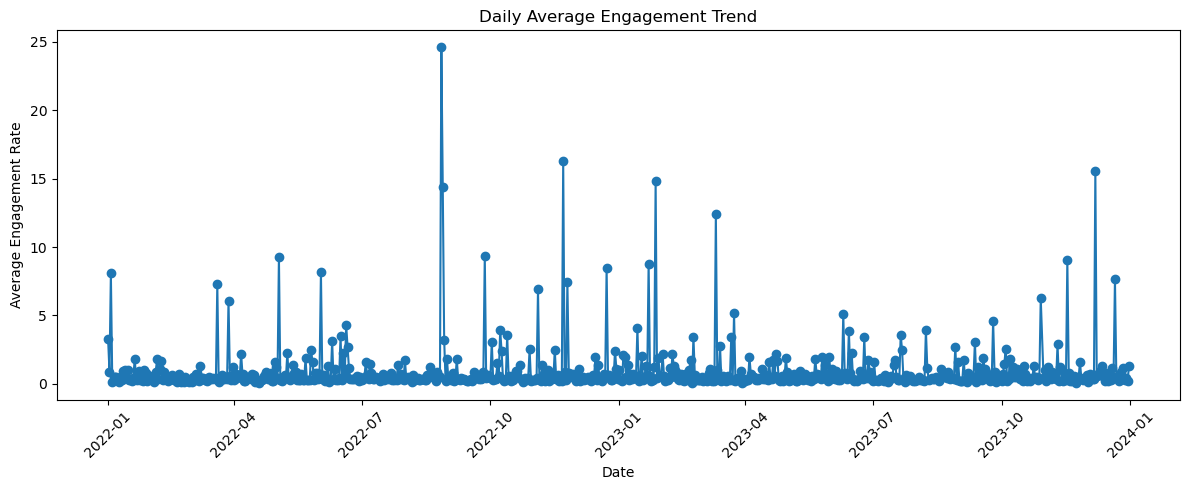

In [252]:
daily_engagement = wrangled_data.groupby(
    wrangled_data['posted_at'].dt.date)['engagement_rate'].mean()

plt.figure(figsize=(12, 5))

plt.plot(
    daily_engagement.index,
    daily_engagement.values,
    marker='o')

plt.title('Daily Average Engagement Trend')
plt.xlabel('Date')
plt.ylabel('Average Engagement Rate')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

> <b> Bar chart: Posts by category</b>

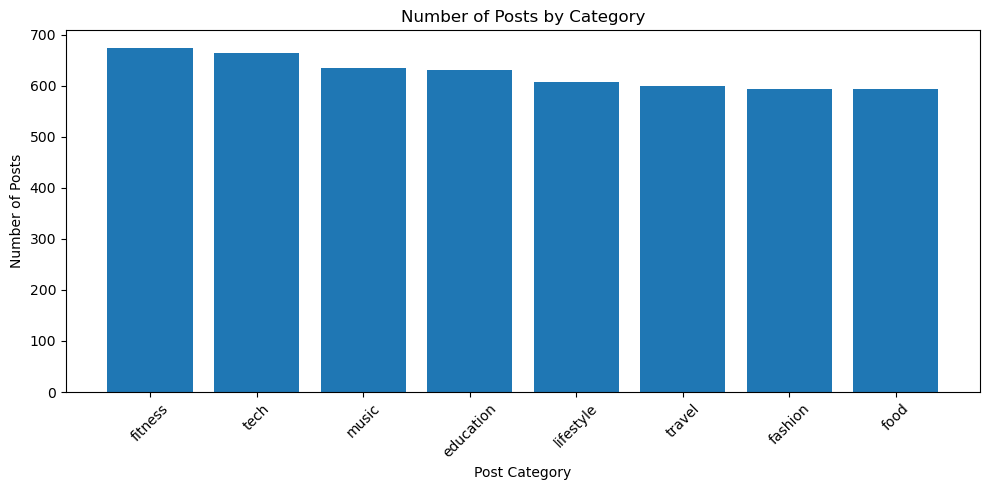

In [253]:
category_counts = wrangled_data['post_category'].value_counts()

plt.figure(figsize=(10, 5))

plt.bar(
    category_counts.index,
    category_counts.values)

plt.title('Number of Posts by Category')
plt.xlabel('Post Category')
plt.ylabel('Number of Posts')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

> <b> Pie chart: Gender distribution</b>

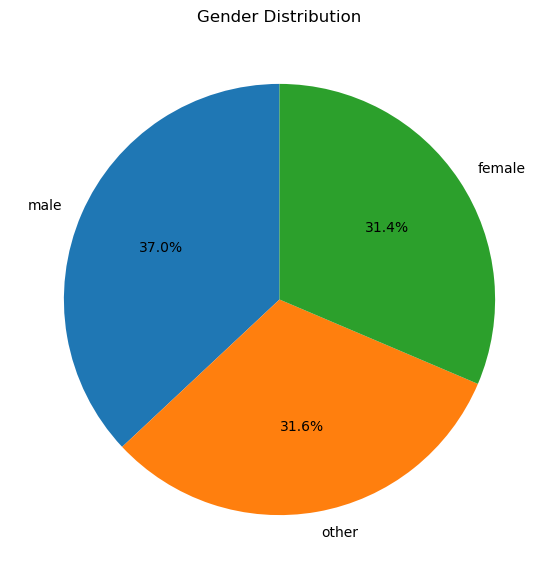

In [254]:
gender_counts = wrangled_data['gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90)

plt.title('Gender Distribution')
plt.show()

> <b> Histogram: Age distribution </b>

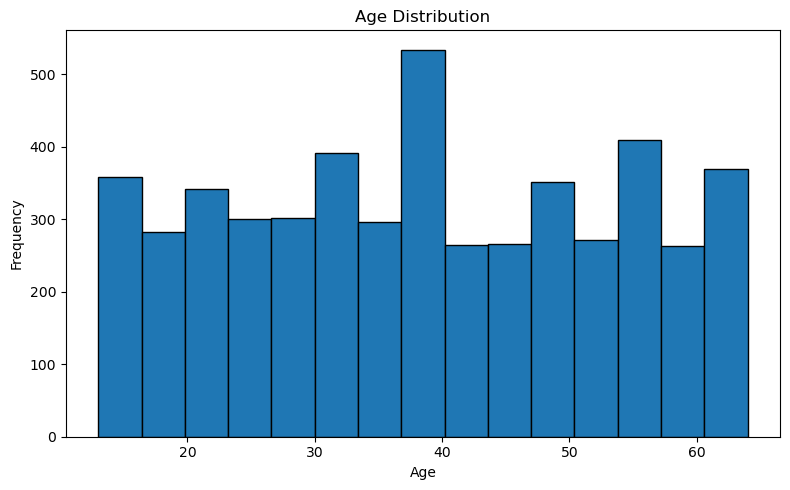

In [255]:
plt.figure(figsize=(8, 5))

plt.hist(
    wrangled_data['age'],
    bins=15,
    edgecolor='black')

plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

> <b>Box plot: Engagement rate</b>

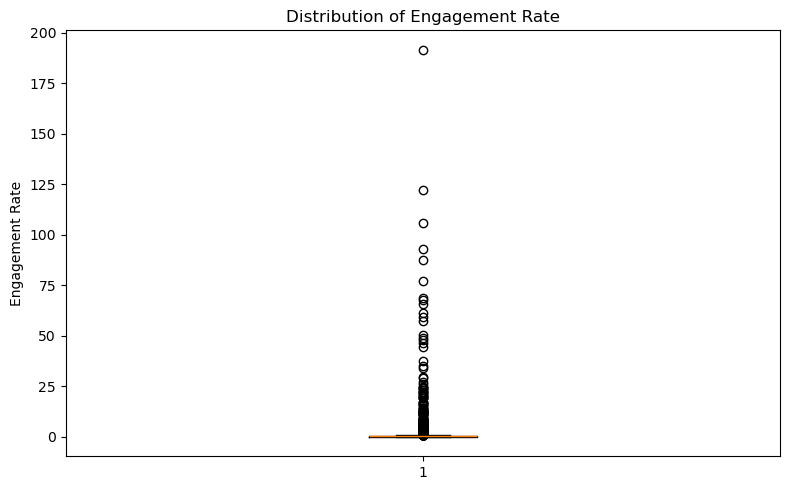

In [256]:
plt.figure(figsize=(8, 5))

plt.boxplot(wrangled_data['engagement_rate'])

plt.title('Distribution of Engagement Rate')
plt.ylabel('Engagement Rate')
plt.tight_layout()
plt.show()

### Seaborn

> <b> Count plot: Post type </b>

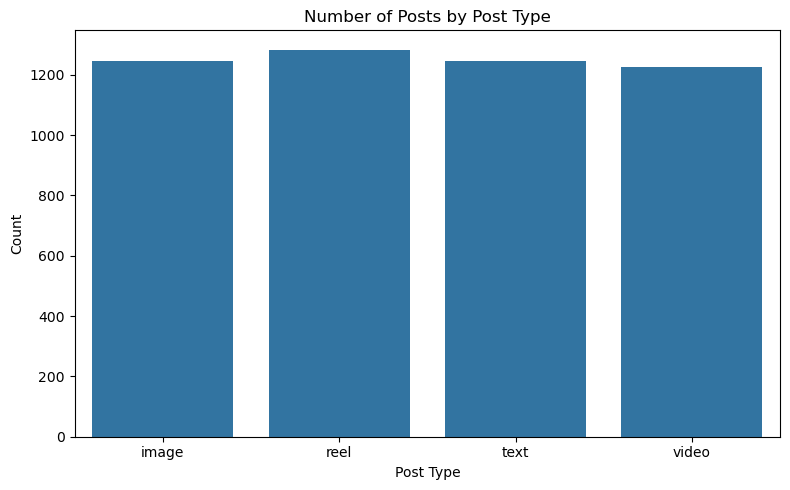

In [257]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=wrangled_data,
    x='post_type')

plt.title('Number of Posts by Post Type')
plt.xlabel('Post Type')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

> <b> Bar plot: Average likes by category</b>

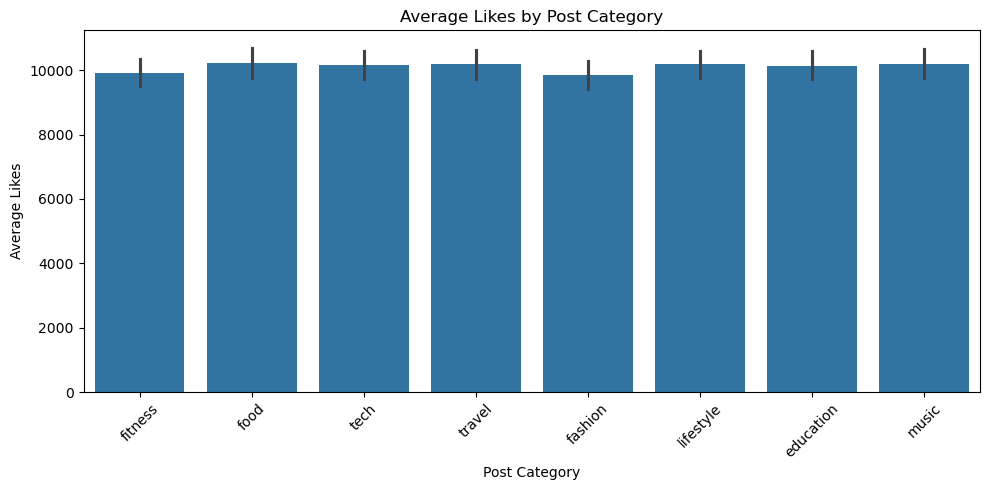

In [258]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=wrangled_data,
    x='post_category',
    y='likes',
    estimator='mean')

plt.title('Average Likes by Post Category')
plt.xlabel('Post Category')
plt.ylabel('Average Likes')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

> <b> Violin plot: Followers vs Sentiment </b> 

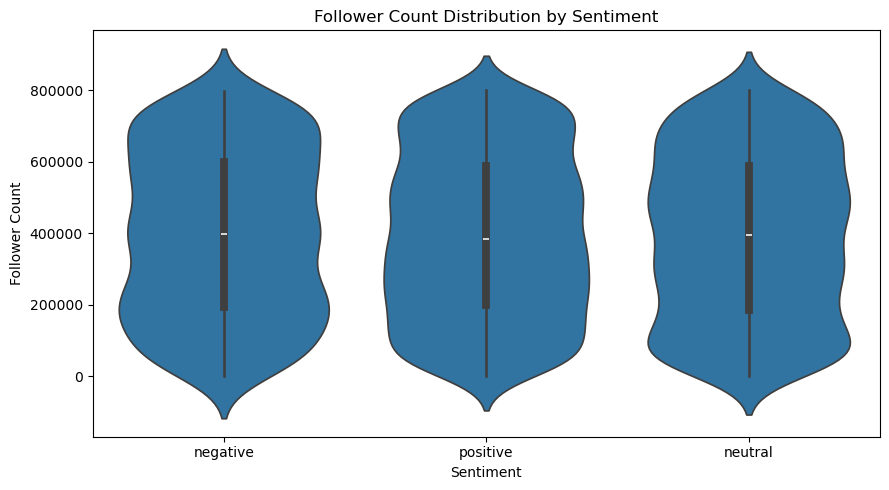

In [259]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=wrangled_data,
    x='sentiment',
    y='follower_count')

plt.title('Follower Count Distribution by Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Follower Count')
plt.tight_layout()
plt.show()

> <b> Pair plot: Numerical features</b>

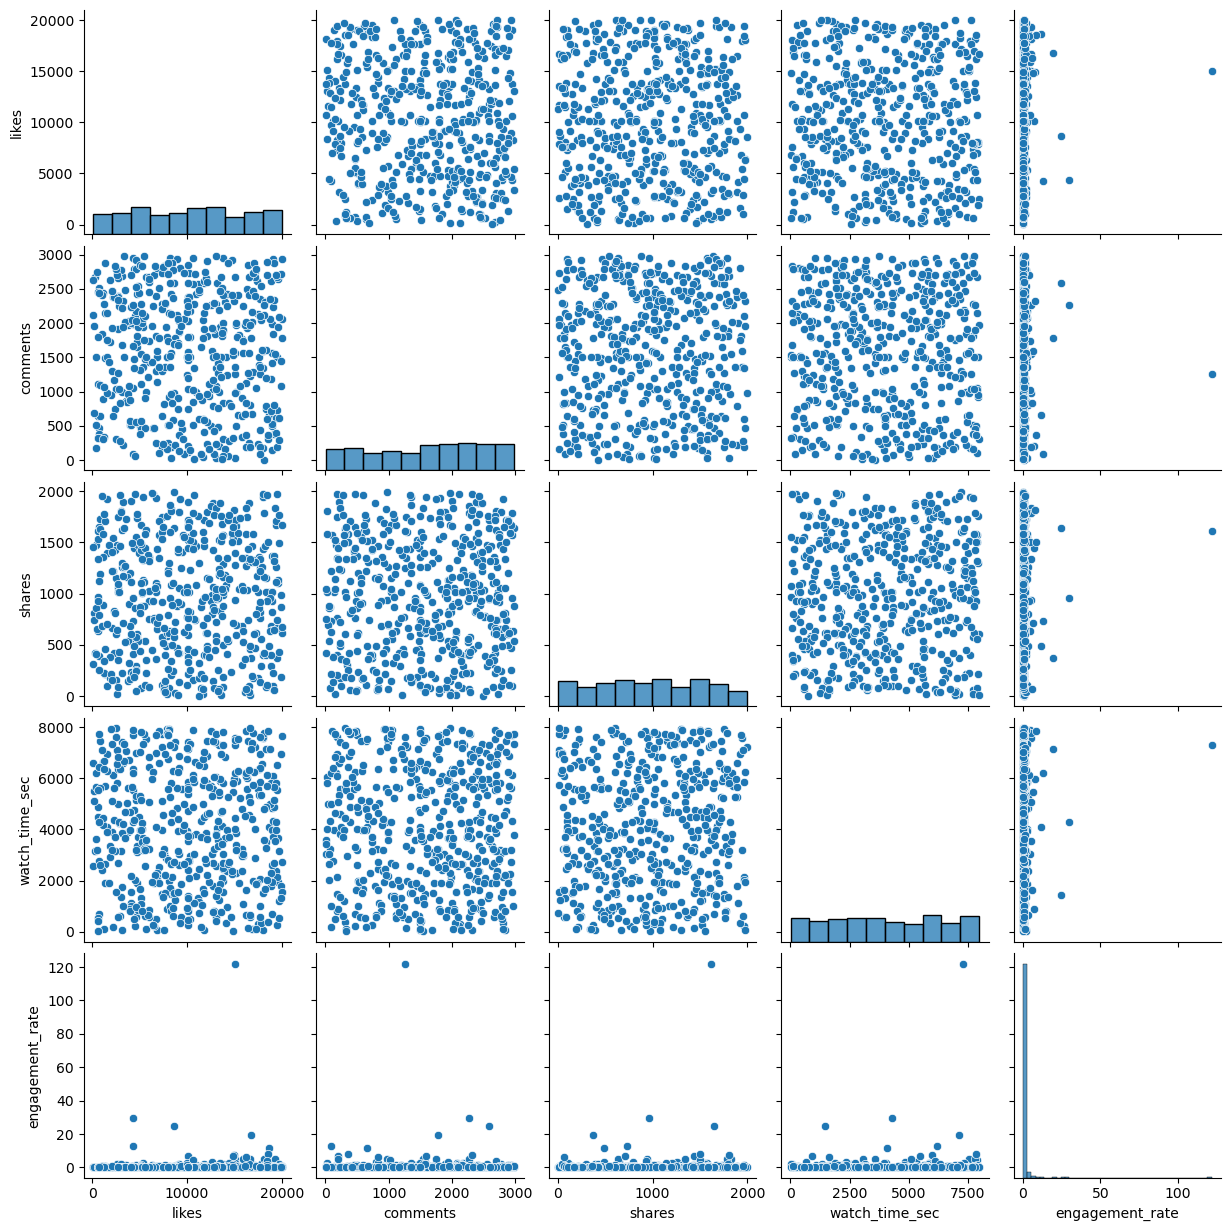

In [260]:
pair_columns = [
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'engagement_rate']

sns.pairplot(
    wrangled_data[pair_columns].sample(
        n=min(500, len(wrangled_data)),
        random_state=42))

plt.show()

> <b> Heatmap: Correlation matrix </b> 

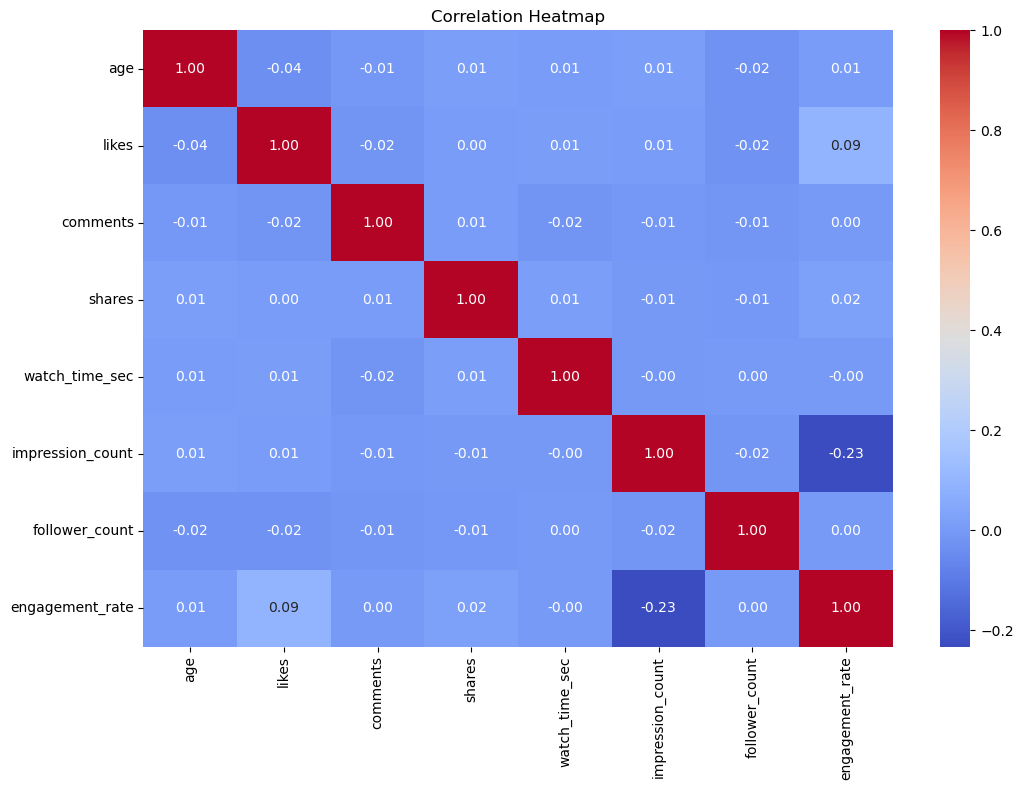

In [261]:
correlation_columns = [
    'age',
    'likes',
    'comments',
    'shares',
    'watch_time_sec',
    'impression_count',
    'follower_count',
    'engagement_rate']

correlation_matrix = wrangled_data[
    correlation_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f')

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

> <b> Swarm plot: Engagement vs Device</b> 

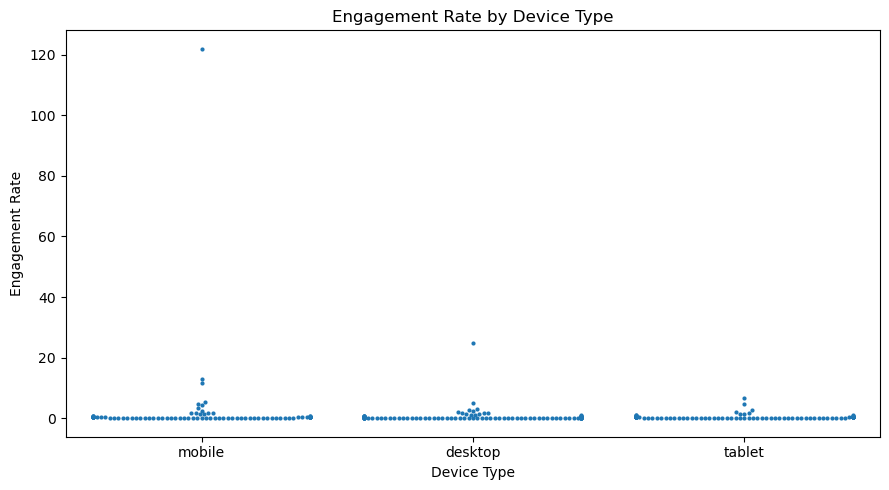

In [262]:
swarm_data = wrangled_data.sample(
    n=min(300, len(wrangled_data)),
    random_state=42)

plt.figure(figsize=(9, 5))

sns.swarmplot(
    data=swarm_data,
    x='device_type',
    y='engagement_rate',
    size=3)

plt.title('Engagement Rate by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Engagement Rate')
plt.tight_layout()
plt.show()

## Plotly (Interactive)

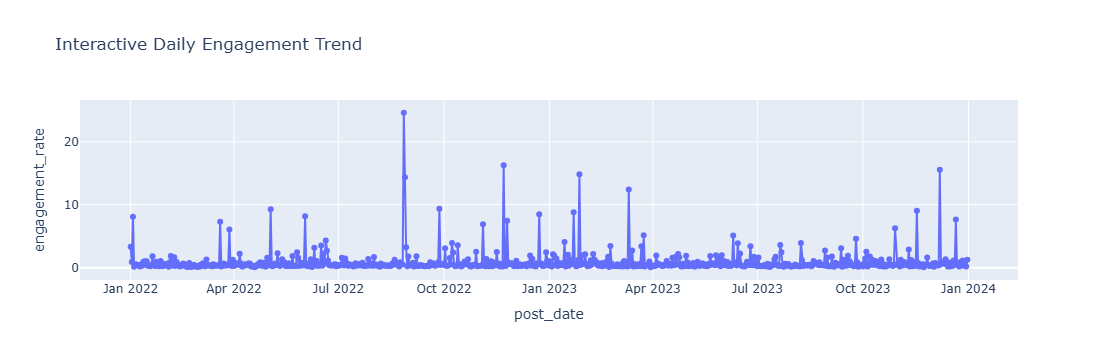

In [263]:
daily_plotly = wrangled_data.copy()

daily_plotly['post_date'] = daily_plotly['posted_at'].dt.date

daily_plotly = daily_plotly.groupby(
    'post_date', as_index=False)['engagement_rate'].mean()

fig = px.line(
    daily_plotly,
    x='post_date',
    y='engagement_rate',
    title='Interactive Daily Engagement Trend',
    markers=True)

fig.show()

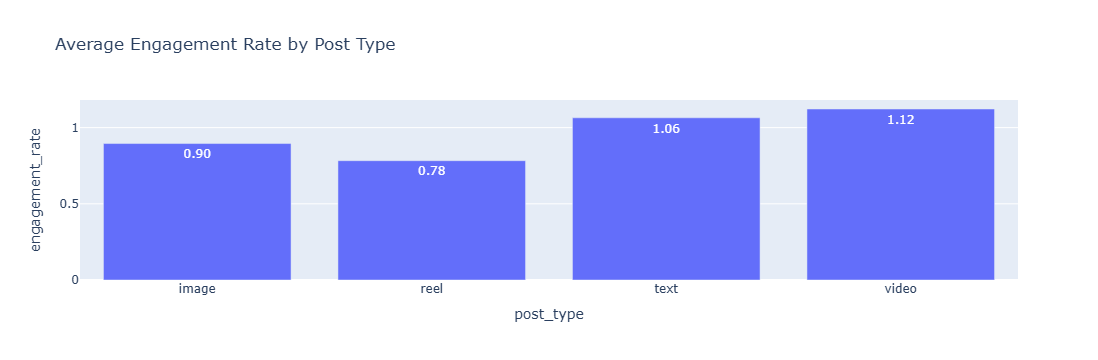

In [264]:
plotly_post_type = wrangled_data.groupby(
    'post_type', as_index=False)['engagement_rate'].mean()

fig = px.bar(
    plotly_post_type,
    x='post_type',
    y='engagement_rate',
    title='Average Engagement Rate by Post Type',
    text_auto='.2f')

fig.show()

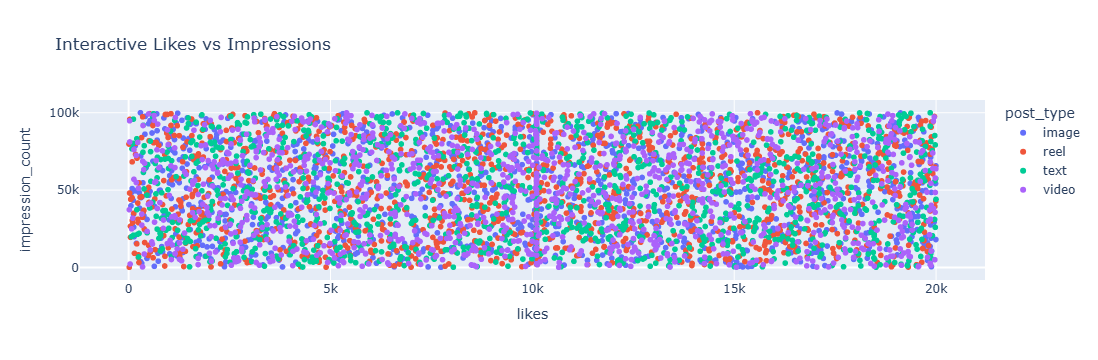

In [265]:
fig = px.scatter(
    wrangled_data,
    x='likes',
    y='impression_count',
    color='post_type',
    hover_data=['post_category', 'sentiment'],
    title='Interactive Likes vs Impressions')

fig.show()

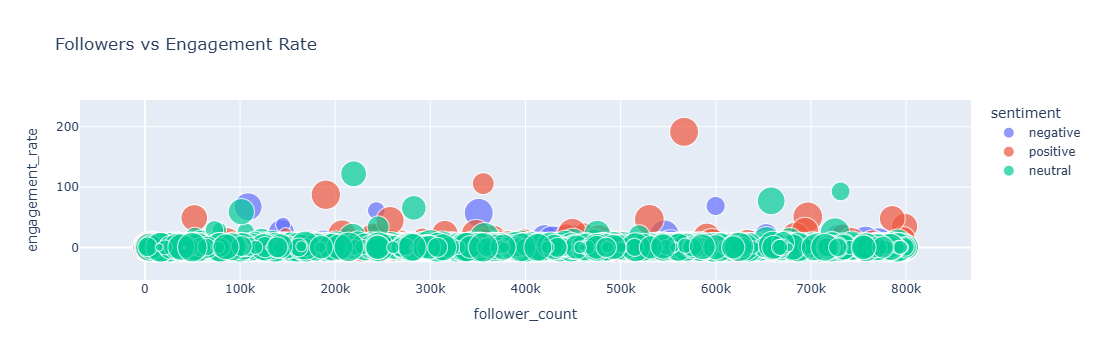

In [266]:
fig = px.scatter(
    wrangled_data,
    x='follower_count',
    y='engagement_rate',
    size='likes',
    color='sentiment',
    hover_data=['post_type', 'post_category'],
    title='Followers vs Engagement Rate',
    size_max=30)

fig.show()

# <b> Final Insights </b> 

# Content Performance

### Highest-engagement post type

In [267]:
post_type_insights = wrangled_data.groupby(
    'post_type'
)['engagement_rate'].mean().sort_values(ascending=False)

display(post_type_insights)

print("Highest-engagement post type:",
      post_type_insights.idxmax())

post_type
video    1.122365
text     1.064549
image    0.895646
reel     0.783047
Name: engagement_rate, dtype: float64

Highest-engagement post type: video


### Best-performing content category

In [268]:
category_insights = wrangled_data.groupby(
    'post_category'
)['engagement_rate'].mean().sort_values(ascending=False)

display(category_insights)

print("Best-performing category:",
      category_insights.idxmax())

post_category
food         1.358628
tech         1.160475
lifestyle    1.091019
music        0.888803
fitness      0.865628
education    0.844222
fashion      0.807109
travel       0.702223
Name: engagement_rate, dtype: float64

Best-performing category: food


### Countries with highest average engagement rate

In [269]:
country_insights = wrangled_data.groupby(
    'country'
)['engagement_rate'].mean().sort_values(ascending=False)

display(country_insights)

print("Country with highest average engagement:",
      country_insights.idxmax())

country
brazil       1.540704
australia    1.324339
france       1.146402
uae          1.112352
canada       0.916659
uk           0.850966
japan        0.769623
germany      0.759000
india        0.655005
usa          0.576580
Name: engagement_rate, dtype: float64

Country with highest average engagement: brazil


# User Trends

### How age affects engagement

In [270]:
age_bins = [12, 20, 30, 40, 50, 65]

age_labels = [
    '13-20',
    '21-30',
    '31-40',
    '41-50',
    '51-64']

wrangled_data['age_group'] = pd.cut(
    wrangled_data['age'],
    bins=age_bins,
    labels=age_labels)

age_insights = wrangled_data.groupby(
    'age_group', observed=False)['engagement_rate'].mean()

display(age_insights)

age_group
13-20    0.802733
21-30    1.018917
31-40    0.843572
41-50    1.103215
51-64    1.020729
Name: engagement_rate, dtype: float64

### Verified account performance

In [271]:
verified_insights = wrangled_data.groupby(
    'is_verified').agg(
    Average_Engagement=('engagement_rate', 'mean'),
    Average_Likes=('likes', 'mean'),
    Average_Comments=('comments', 'mean'),
    Average_Watch_Time=('watch_time_sec', 'mean'))

display(verified_insights)

,Average_Engagement,Average_Likes,Average_Comments,Average_Watch_Time
is_verified,,,,
False,0.954744,10137.216515,1505.511401,4005.201240
True,1.054250,9824.544513,1469.573499,4101.494824


# Behavioral Insights

### Best time of day for impressions

In [272]:
wrangled_data['post_hour'] = wrangled_data['posted_at'].dt.hour

hour_insights = wrangled_data.groupby(
    'post_hour'
)['impression_count'].mean().sort_values(ascending=False)

display(hour_insights)

print("Best posting hour:",
      hour_insights.idxmax())

post_hour
0    50013.7328
Name: impression_count, dtype: float64

Best posting hour: 0


### Device type impact on watch time

In [273]:
device_insights = wrangled_data.groupby(
    'device_type').agg(
    Average_Watch_Time=('watch_time_sec', 'mean'),
    Average_Impressions=('impression_count', 'mean'),
    Average_Engagement=('engagement_rate', 'mean')).sort_values(
    by='Average_Watch_Time',
    ascending=False)

display(device_insights)

,Average_Watch_Time,Average_Impressions,Average_Engagement
device_type,,,
mobile,4087.830760,49516.948931,1.123999
tablet,3979.736429,49597.971049,0.804560
desktop,3974.792521,50934.068758,0.962006


# Sentiment Analysis

### Which sentiment performs best?

In [274]:
sentiment_insights = wrangled_data.groupby(
    'sentiment'
).agg(
    Average_Engagement=('engagement_rate', 'mean'),
    Average_Likes=('likes', 'mean'),
    Average_Comments=('comments', 'mean'),
    Average_Shares=('shares', 'mean'),
    Total_Posts=('post_id', 'count')).sort_values(
    by='Average_Engagement',
    ascending=False)

display(sentiment_insights)

print("Best-performing sentiment:",
      sentiment_insights['Average_Engagement'].idxmax())

,Average_Engagement,Average_Likes,Average_Comments,Average_Shares,Total_Posts
sentiment,,,,,
negative,1.038486,10208.112500,1516.094792,1007.307292,960
neutral,0.991170,9923.208906,1528.404060,996.565160,1527
positive,0.919744,10180.077199,1480.650617,1005.086749,2513


Best-performing sentiment: negative


### Behaviour of negative and neutral sentiment posts

In [275]:
negative_neutral_data = wrangled_data[
    wrangled_data['sentiment'].isin(['negative', 'neutral'])]

negative_neutral_insights = negative_neutral_data.groupby(
    'sentiment').agg(
    Total_Posts=('post_id', 'count'),
    Average_Likes=('likes', 'mean'),
    Average_Comments=('comments', 'mean'),
    Average_Shares=('shares', 'mean'),
    Average_Watch_Time=('watch_time_sec', 'mean'),
    Average_Impressions=('impression_count', 'mean'),
    Average_Engagement=('engagement_rate', 'mean'))

display(negative_neutral_insights)

,Total_Posts,Average_Likes,Average_Comments,Average_Shares,Average_Watch_Time,Average_Impressions,Average_Engagement
sentiment,,,,,,,
negative,960,10208.112500,1516.094792,1007.307292,4054.639583,50191.960417,1.038486
neutral,1527,9923.208906,1528.404060,996.565160,4031.823183,49515.971185,0.991170
